# Non-extensive (Tsallis) parametric unfolding of an IAEA Compendium spectrum (`unfold_nonextensive`)

This notebook applies the non-extensive (Tsallis) parameterized unfolding
method of

> Y. ZhangSun, Z. Li, C. Su, D. Li, S. Guo, Z. Wu, X. Zhang,
> "Determination of Neutron Spectrum for Nuclear Reactor Based on
> Non-extensive Statistical Theory", *Applied Radiation and Isotopes*
> (2026), DOI 10.1016/j.apradiso.2026.113015.

A reactor neutron field is an open system that does not obey the
ergodicity hypothesis of Boltzmann-Gibbs statistics.  The method
therefore maximizes the **Tsallis entropy**

$$S_q = k\,\frac{1 - \sum_i p_i^{\,q}}{q - 1}$$

under the normalization, particle-number and average-energy constraints
of the neutron field.  The resulting flux density is a **q-exponential**
(paper eq. (6)); including an absorption factor $E^{-n}$ (eq. (7)) and
superposing the thermal, intermediate and fast components gives the
parameterized prior (eq. (8))

$$\varphi_k(E) = C_k\,\exp_q\!\big(-(\beta_k E^{-1/2} + g_k E)\big)\,E^{-n_k},
\qquad \exp_q(x) = [1 + (1-q)x]^{1/(1-q)},$$

with $E$ in eV and the component nodes fixed at $0.5$ eV and $1\times10^5$ eV.
Each component carries five parameters $(C_k, \beta_k, g_k, q_k, n_k)$, i.e.
**fifteen free parameters** in total.  They are fitted to the measured
readings by minimizing the sum of squared **relative** deviations of the
activation rates (paper eq. (9))

$$R(\theta) = \sum_i \left(\frac{a_i^{\text{cal}}(\theta) - a_i^{\text{exp}}}{a_i^{\text{exp}}}\right)^2 .$$

The paper solves this nonlinear least-squares problem with the
initial-value-independent global optimizer of the 1stOpt software; here
a differential-evolution global search is followed by a bounded
nonlinear least-squares refinement.  The $q \to 1$ limit recovers the
Boltzmann-Gibbs (plain exponential) distribution.

In [1]:
# %pip install bssunfold pandas numpy matplotlib

## 1. Detector response functions

We use the built-in GSF response functions (10 Bonner spheres, `0in` -
`18in`, 60 energy bins from 1e-9 to ~631 MeV).

Detector grid: 60 bins, 1.0e-09 - 631.0 MeV
Spheres: 0in, 2in, 3in, 5in, 6in, 8in, 10in, 12in, 15in, 18in


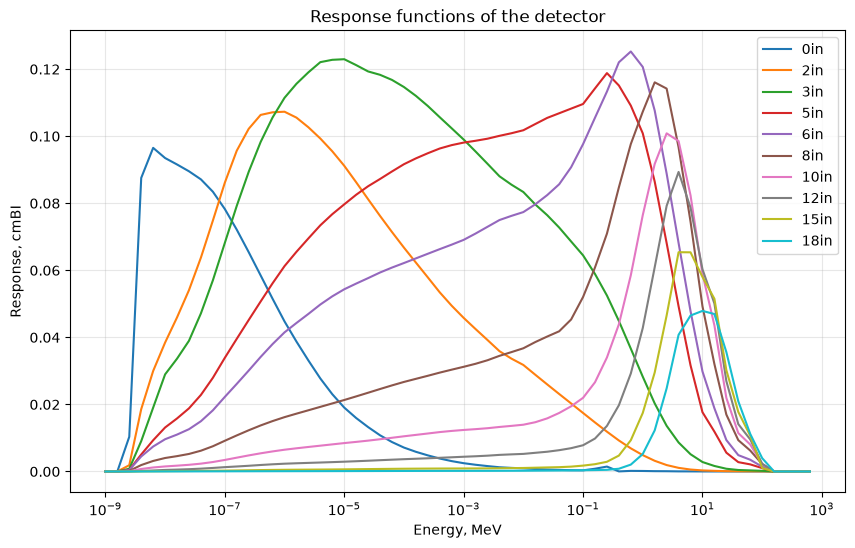

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bssunfold import Detector, RF_GSF
from bssunfold.core import (
    NONEXTENSIVE_PARAM_NAMES,
    nonextensive_model,
)
from bssunfold.utils.comparison import compare_spectra

detector = Detector(RF_GSF)
E = detector.E_MeV
names = detector.detector_names
print(f"Detector grid: {detector.n_energy_bins} bins, "
      f"{E[0]:.1e} - {E[-1]:.1f} MeV")
print("Spheres:", ", ".join(names))
detector.plot_response_functions()

## 2. IAEA Compendium reference spectrum -> detector readings

The compendium CSV stores 61-point Monte-Carlo spectra on its own energy
grid, which differs slightly from the 60-bin detector grid, so the
ground truth is interpolated onto the detector grid *for evaluation
only*.  The readings are the spectrum folded with the response
functions.

In [3]:
reference_csv = pd.read_csv(
    '../tests/MonteCarlo_Calculated_spectra_from_IAEA_Comp_for_comparison.csv'
)
print(f"Reference CSV: {len(reference_csv)} rows, "
      f"{len(reference_csv.columns) - 1} spectra, "
      f"{reference_csv['E_MeV'].min():.1e} - "
      f"{reference_csv['E_MeV'].max():.0f} MeV")

SPECTRUM = 't4-14-s.txt_1'   # IAEA Compendium BSA benchmark case

readings = detector.get_effective_readings_for_spectra(
    reference_csv[['E_MeV', SPECTRUM]]
)
print("Effective readings:")
for nm in names:
    print(f"  {nm:>5s}: {readings[nm]:.4g}")

# Ground truth on the detector grid (for evaluation only)
phi_true = np.interp(
    E, reference_csv['E_MeV'].values, reference_csv[SPECTRUM].values
)
print(f"\nground-truth integral: {np.sum(phi_true * detector.ln_steps):.4g}")

Reference CSV: 61 rows, 20 spectra, 1.0e-09 - 631 MeV
Effective readings:
    0in: 0.06677
    2in: 0.0901
    3in: 0.1382
    5in: 0.1639
    6in: 0.1407
    8in: 0.08047
   10in: 0.03924
   12in: 0.01789
   15in: 0.006419
   18in: 0.003085

ground-truth integral: 1.001


## 3. Non-extensive unfolding

The paper fits the fifteen parameters to **33 activation channels**, so the
problem is overdetermined and the fitted spectrum is essentially unique.
Here we only have the **10 Bonner spheres** of the GSF set, so the problem
is *underdetermined*: many parameter vectors reproduce the readings while
differing in pointwise shape.  We therefore demonstrate two strategies:

* **global search, no prior** (`search="global"`) — a differential-evolution
  global search of the fifteen-parameter box followed by a least-squares
  refinement, mirroring the initial-value-independent 1stOpt workflow of
  the paper.  The folded readings are reproduced well, but the pointwise
  shape is not unique;
* **informed a-priori spectrum** (`search="local"`, `initial_spectrum=...`)
  — the paper's own recommendation: fit eq. (8) to an a-priori (e.g.
  simulated) spectrum to obtain the starting parameters, then refine
  against the readings.  This anchors the solution to a physical shape.

The fitted fifteen parameters, the objective $R$ (paper eq. (9)) and the
maximum relative deviation of the folded readings are reported.

In [4]:
result_global = detector.unfold_nonextensive(
    readings, search="global", ga_maxiter=30, random_state=0,
    save_result=False,
)

# Informed a-priori spectrum (as if from a shield-design / Monte-Carlo
# calculation): the benchmark shape at half scale plus an offset.
phi_prior = 0.5 * phi_true + 0.1 * np.max(phi_true)
result_informed = detector.unfold_nonextensive(
    readings, search="local", initial_spectrum=phi_prior, save_result=False,
)

for label, result in [("global, no prior", result_global),
                      ("informed prior", result_informed)]:
    mp = result["model_params"]
    print(f"\n{label}: method={result['method']!r}")
    print(f"  fitted q values : "
          f"{[round(mp['q_th'], 2), round(mp['q_epi'], 2), round(mp['q_f'], 2)]}")
    print(f"  objective R     : {mp['objective']:.4e}")
    print(f"  max rel. dev.   : {mp['max_relative_deviation']:.3%}")
    print(f"  residual norm   : {result['residual_norm']:.4e}")
    m = compare_spectra(
        phi_true, result["spectrum"],
        metrics=["relative_flux_error", "pearson_r", "comprehensive_score"],
    )
    print(f"  score           : {m['comprehensive_score']:.3f}  "
          f"(pearson_r={m['pearson_r']:.3f})")


global, no prior: method='Tsallis non-extensive'
  fitted q values : [0.95, 1.1, 3.72]
  objective R     : 2.2653e-03
  max rel. dev.   : 3.088%
  residual norm   : 3.6820e-03
  score           : 1.915  (pearson_r=0.270)

informed prior: method='Tsallis non-extensive'
  fitted q values : [1.97, 0.23, 3.21]
  objective R     : 4.3302e-03
  max rel. dev.   : 4.276%
  residual norm   : 4.3540e-03
  score           : 0.682  (pearson_r=0.502)


## 4. Fitted spectrum and component decomposition

Substituting the fitted parameters into eq. (8) yields the reconstructed
spectrum.  Isolating the three components (thermal, intermediate, fast)
shows how the q-exponentials shape each energy region: the thermal
component carries the low-energy hardening, the intermediate region is
close to the canonical $1/E$ tail, and the fast component describes the
fission peak.

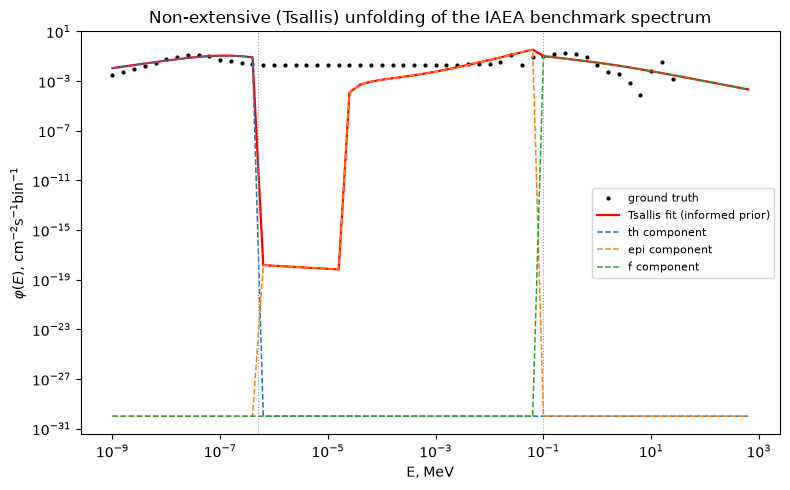

In [5]:
mp = result_informed["model_params"]
theta = np.array([mp[name] for name in NONEXTENSIVE_PARAM_NAMES])
phi_fit = nonextensive_model(E, theta)

# Isolate each component by zeroing the amplitudes of the others.
component_curves = {}
for comp in ("th", "epi", "f"):
    theta_comp = theta.copy()
    for name in NONEXTENSIVE_PARAM_NAMES:
        if name == f"log10C_{comp}":
            continue
        if name.startswith("log10C_"):
            theta_comp[NONEXTENSIVE_PARAM_NAMES.index(name)] = -60.0
    component_curves[comp] = nonextensive_model(E, theta_comp)

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(E, phi_true, "k.", ms=4, label="ground truth")
ax.loglog(E, phi_fit, "r-", lw=1.6, label="Tsallis fit (informed prior)")
for comp, cur in component_curves.items():
    ax.loglog(E, np.maximum(cur, 1e-30), "--", lw=1.1,
              label=f"{comp} component")
ax.axvline(0.5e-6, color="0.6", lw=0.8, ls=":")
ax.axvline(0.1, color="0.6", lw=0.8, ls=":")
ax.set(
    xlabel="E, MeV",
    ylabel=r"$\varphi(E)$, cm$^{-2}$s$^{-1}$bin$^{-1}$",
    title="Non-extensive (Tsallis) unfolding of the IAEA benchmark spectrum",
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Relative deviations of the activation rates

Figure 7 of the paper reports the relative deviation between the
calculated and experimental activation rates for every reaction channel.
The per-reading relative deviations are returned in
`model_params['relative_deviations']`.

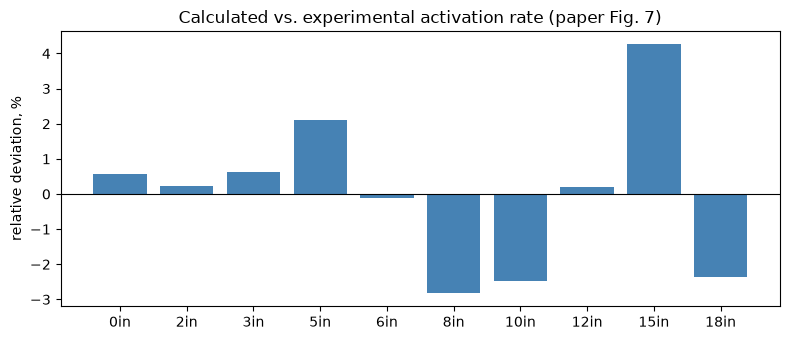

In [6]:
rel = result_informed["model_params"]["relative_deviations"]
labels = [n for n in names if n in readings]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(labels, [100.0 * (v if v is not None else 0.0) for v in rel],
       color="steelblue")
ax.axhline(0.0, color="k", lw=0.8)
ax.set(ylabel="relative deviation, %",
       title="Calculated vs. experimental activation rate (paper Fig. 7)")
plt.tight_layout()
plt.show()

## 6. Baselines

Two widely used iterative baselines — **GRAVEL** (weighted log-domain
least squares) and **MLEM** — start from the same flat prior for
comparison.

In [7]:
grav = detector.unfold_gravel(
    readings, initial_spectrum=np.full(E.size, 0.5),
    max_iterations=2000, save_result=False,
)
mlem = detector.unfold_mlem(
    readings, initial_spectrum=np.full(E.size, 0.5),
    max_iterations=2000, save_result=False,
)

labels = ["non-extensive (no prior)", "non-extensive (informed)",
          "GRAVEL", "MLEM"]
spectra = [result_global["spectrum"], result_informed["spectrum"],
           grav["spectrum"], mlem["spectrum"]]
print(f"{'method':<26s} {'score':>8s} {'pearson_r':>10s} {'rel.flux err':>13s}")
for label, spec in zip(labels, spectra):
    m = compare_spectra(
        phi_true, spec,
        metrics=["comprehensive_score", "pearson_r", "relative_flux_error"],
    )
    print(f"{label:<26s} {m['comprehensive_score']:>8.3f} "
          f"{m['pearson_r']:>10.3f} {m['relative_flux_error']:>13.3f}")

method                        score  pearson_r  rel.flux err
non-extensive (no prior)      1.915      0.270         2.050
non-extensive (informed)      0.682      0.502         0.933
GRAVEL                        2.954     -0.146         2.881
MLEM                          0.008      0.834         0.425


## 7. Summary

* `unfold_nonextensive` implements the non-extensive (Tsallis) parameterized
  prior of ZhangSun et al. (2026): a three-component q-exponential spectrum
  (eq. (8)) with fifteen free parameters, fitted by minimizing the sum of
  squared relative deviations of the activation rates (eq. (9)).
* The q-exponential $\exp_q$ reduces to the Boltzmann-Gibbs exponential as
  $q \to 1$; the fitted values of $q$ quantify the deviation of each energy
  region from classical statistics.
* The global search mirrors the initial-value-independent optimizer of the
  original software; `search="local"` refines only from the starting vector.
* With the 10 Bonner spheres of the GSF set the fifteen-parameter problem is
  underdetermined (the paper used 33 activation channels), so the folded
  readings are reproduced well while the pointwise shape is not unique.
  Supplying an a-priori spectrum (`initial_spectrum=...`) anchors the
  solution, as recommended in section 4 of the paper.
* Statistical uncertainties are available via `calculate_errors=True`
  (Monte-Carlo propagation).